# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.




1. Cargue los textos originales.


In [16]:
import nltk
import re
from nltk.corpus import gutenberg
import pandas as pd
import time
import matplotlib.pyplot as plt

nltk.download("gutenberg")

[nltk_data] Downloading package gutenberg to
[nltk_data]     C:\Users\Juan\AppData\Roaming\nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


True

2. Identifique el número de documentos y sus tamaños.

In [2]:
archivos = gutenberg.fileids()

print(f"Número de documentos: {len(archivos)}")  # Imprime la longitud del archivo seleccionados
print("=========================================")
def size_and_name(archivos):
    sizetotal = 0
    for archivo in archivos:
        nombre = archivo     # Obtiene el nombre del archivo    
        ruta = gutenberg.abspath(archivo)
        tamaño = ruta.file_size()  # Obtiene el tamaño del archivo en bytes
        sizetotal += tamaño
        print(f"Nombre del archivo: {nombre}, Tamaño: {tamaño} bytes o {tamaño / 1024:.2f} KB")   # Imprime el nombre y tamaño del archivo
    print(f"Tamaño total: {sizetotal} bytes o {sizetotal / 1024:.2f} KB")  # Imprime el tamaño total de todos los archivos

size_and_name(archivos)

Número de documentos: 18
Nombre del archivo: austen-emma.txt, Tamaño: 887071 bytes o 866.28 KB
Nombre del archivo: austen-persuasion.txt, Tamaño: 466292 bytes o 455.36 KB
Nombre del archivo: austen-sense.txt, Tamaño: 673022 bytes o 657.25 KB
Nombre del archivo: bible-kjv.txt, Tamaño: 4332554 bytes o 4231.01 KB
Nombre del archivo: blake-poems.txt, Tamaño: 38153 bytes o 37.26 KB
Nombre del archivo: bryant-stories.txt, Tamaño: 249439 bytes o 243.59 KB
Nombre del archivo: burgess-busterbrown.txt, Tamaño: 84663 bytes o 82.68 KB
Nombre del archivo: carroll-alice.txt, Tamaño: 144395 bytes o 141.01 KB
Nombre del archivo: chesterton-ball.txt, Tamaño: 457450 bytes o 446.73 KB
Nombre del archivo: chesterton-brown.txt, Tamaño: 406629 bytes o 397.10 KB
Nombre del archivo: chesterton-thursday.txt, Tamaño: 320525 bytes o 313.01 KB
Nombre del archivo: edgeworth-parents.txt, Tamaño: 935158 bytes o 913.24 KB
Nombre del archivo: melville-moby_dick.txt, Tamaño: 1242990 bytes o 1213.86 KB
Nombre del archiv


3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.
Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.



In [3]:
#Usaremos expresiones regulares para encontrar palabras en los textos. La expresión regular que usaremos es la siguiente:
patron = r"[a-z0-9]+(?:'[a-z]+)*"
#Elegimos esta expresión regular porque nos permite encontrar palabras que contengan letras minúsculas y apóstrofes, lo que nos permitirá capturar palabras como "don't" o "it's", y tambien incluimos números para incluir años
# Ademas que la coleccion principalmente esta en ingles y las palabras en ingles no tienen acentos, por lo que no es necesario incluirlos en la expresion regular.
#Decidimos eliminar puntuación, por eso quiza G.K se transforme en g k pero es la cofiguración seleccionada.
def preprocesamiento(texto):
    texto = texto.lower()  # Convertimos el texto a minúsculas
    texto =texto.replace("’", "'") # Reemplazamos el apóstrofe tipográfico por el apóstrofe simple
    #Tokenizacion 
    palabras = re.findall(patron, texto)  
    return palabras

originales = {}
procesados={}

def token_and_store(archivos):
    for archivo in archivos:
        texto_original = gutenberg.raw(archivo)
        tokens = preprocesamiento(texto_original)
        originales[archivo] = texto_original
        procesados[archivo] = tokens


token_and_store(archivos)




### Previsualización de los datos

In [4]:
datos = []
def view_dataframe(originales, procesados, archivos):
    for archivo in archivos:
        datos.append({
            "Documento": archivo,
            "Original (preview)": originales[archivo][:60],
            "Procesado (preview)": " ".join(procesados[archivo][:10]),
            "Total palabras": len(procesados[archivo])
        })

    tabla = pd.DataFrame(datos)
    display(tabla)
        

        

view_dataframe(originales, procesados, archivos)


,Documento,Original (preview),Procesado (preview),Total palabras
0,austen-emma.txt,[Emma by Jane Austen 1816]\n\nVOLUME I\n\nCHAP...,emma by jane austen 1816 volume i chapter i emma,160999
1,austen-persuasion.txt,[Persuasion by Jane Austen 1818]\n\n\nChapter ...,persuasion by jane austen 1818 chapter 1 sir w...,83659
2,austen-sense.txt,[Sense and Sensibility by Jane Austen 1811]\n\...,sense and sensibility by jane austen 1811 chap...,119965
3,bible-kjv.txt,[The King James Bible]\n\nThe Old Testament of...,the king james bible the old testament of the ...,852256
4,blake-poems.txt,[Poems by William Blake 1789]\n\n \nSONGS OF I...,poems by william blake 1789 songs of innocence...,6839
5,bryant-stories.txt,[Stories to Tell to Children by Sara Cone Brya...,stories to tell to children by sara cone bryan...,46321
6,burgess-busterbrown.txt,[The Adventures of Buster Bear by Thornton W. ...,the adventures of buster bear by thornton w bu...,15969
7,carroll-alice.txt,[Alice's Adventures in Wonderland by Lewis Car...,alice's adventures in wonderland by lewis carr...,26688
8,chesterton-ball.txt,[The Ball and The Cross by G.K. Chesterton 190...,the ball and the cross by g k chesterton 1909,82249
9,chesterton-brown.txt,[The Wisdom of Father Brown by G. K. Chesterto...,the wisdom of father brown by g k chesterton 1914,72391


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [5]:

#Funcion
def busqueda_secuencial(termino, corpus=procesados):
    encontrados = []
    termino = termino.lower()
    for archivo, tokens in corpus.items():
        for token in tokens:
            if token == termino:
                encontrados.append(archivo)
                break 
    return encontrados

#Términos frecuentes
frecuentes = ["the", "and", "of", "to", "a"]

#Terminos poco frecuentes
poco_frecuentes = ["whale", "ship", "yellow", "captain", "harpoon"]

def buscar_terminos(terminos):
    for termino in terminos:
        encontrados = busqueda_secuencial(termino)
        print(f"El término '{termino}' se encontró en los siguientes documentos: {encontrados}")
print("="*25,"Frecuentes","="*25)
buscar_terminos(frecuentes)
print("="*25,"Pocos frecuentes","="*25)
buscar_terminos(poco_frecuentes)

========================= Frecuentes =========================
El término 'the' se encontró en los siguientes documentos: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
El término 'and' se encontró en los siguientes documentos: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', '

**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [6]:

def tiempos_de_busqueda(funcion, termino, n):
    promedios = {}
    tiempos = []
    for _ in range(n):
        inicio = time.perf_counter_ns()
        funcion(termino)
        fin = time.perf_counter_ns()
        tiempos.append((fin - inicio) / 1000000)  # Convertir a milisegundos
    return (sum(tiempos) / len(tiempos))



def tiempo_mult_busquedas(funcion, terminos, n):
    promedios = {}
    solo_proms_no_termino = []
    #Cambiar el return conforme a lo que se necesite, si se quiere el promedio de cada termino o solo los promedios sin el termino
    for termino in terminos:
        tiempo = tiempos_de_busqueda(funcion, termino, n)
        promedios.update({termino: tiempo})
        solo_proms_no_termino.append(tiempo)
    print("Promedios de tiempo de búsqueda (en milisegundos):")
    for termino, promedio in promedios.items():
        print(f"Término: '{termino}', Tiempo promedio: {promedio:.6f} ms")
    return solo_proms_no_termino

#Termino inventado 

prom = tiempos_de_busqueda(busqueda_secuencial, "xyzabc", 30)
print(f"Tiempo promedio de búsqueda para el término 'xyzabc': {prom:.6f} ms")

#terminos frecuentes
tiempo_mult_busquedas(busqueda_secuencial, frecuentes, 30)


Tiempo promedio de búsqueda para el término 'xyzabc': 33.102047 ms
Promedios de tiempo de búsqueda (en milisegundos):
Término: 'the', Tiempo promedio: 0.005700 ms
Término: 'and', Tiempo promedio: 0.008270 ms
Término: 'of', Tiempo promedio: 0.005167 ms
Término: 'to', Tiempo promedio: 0.027667 ms
Término: 'a', Tiempo promedio: 0.018303 ms


[0.0057,
 0.008270000000000001,
 0.005166666666666667,
 0.027666666666666666,
 0.018303333333333335]

**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.



In [7]:
def posting_vocabulario(corpus):
    indice = {}
    for archivo, tokens in corpus.items():
        for token in tokens:
            if token not in indice:
                indice[token] = set()
            indice[token].add(archivo)   
    return dict(sorted(indice.items()))


indice = posting_vocabulario(procesados)

print("Total de términos únicos(Vocabulario):", len(indice))

print("Documentos que contienen 'whale' (Posting):")
print(sorted(indice.get("whale", set())))

Total de términos únicos(Vocabulario): 43825
Documentos que contienen 'whale' (Posting):
['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']


Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

In [8]:
def get_DF_posting(indice):
    datos = []
    for termino, documentos in indice.items():
        df = len(documentos)
        datos.append({
            "Termino": termino,
            "Lista Posting": sorted(documentos),
            "DF": df,
        })

    tabla = pd.DataFrame(datos)
    display(tabla)


get_DF_posting(indice)

,Termino,Lista Posting,DF
0,0,[whitman-leaves.txt],1
1,00,[chesterton-ball.txt],1
2,000,"[austen-emma.txt, chesterton-ball.txt, melvill...",3
3,00021053,[milton-paradise.txt],1
4,00081429,[milton-paradise.txt],1
...,...,...,...
43820,zur,[bible-kjv.txt],1
43821,zuriel,[bible-kjv.txt],1
43822,zurishaddai,[bible-kjv.txt],1
43823,zuyder,[whitman-leaves.txt],1


Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [9]:
def buscar_invertido_termino(termino, indice=indice):
    return sorted(indice.get(termino.lower(), set()))


def buscar_and(termino1, termino2):
    posting1 = indice.get(termino1.lower(), set())
    posting2 = indice.get(termino2.lower(), set())
    return sorted(posting1 & posting2)

def buscar_or(termino1, termino2):
    posting1 = indice.get(termino1.lower(), set())
    posting2 = indice.get(termino2.lower(), set())
    return sorted(posting1 | posting2)

def buscar_not(termino, procesados):
    todos_documentos = set(procesados.keys())
    posting = indice.get(termino.lower(), set())
    return sorted(todos_documentos - posting)



print("Un término:", sorted(buscar_invertido_termino("whale", indice)))

print("AND:", sorted(buscar_and("love", "heart")))

print("OR:", sorted(buscar_or("love", "heart")))

print("NOT:", sorted(buscar_not("the", procesados)))


Un término: ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
AND: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'whitman-leaves.txt']
OR: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
NOT: []


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [36]:
def obtener_identificadores(funcion, termino):
    return funcion(termino)
    



def comparar_resultados(busqueda_secuencial, buscar_invertido_termino, terminos, n=30):
    #Terminos poco frecuentes
    print("="*25,"Búsqueda Secuencial","="*25)
    promsec_lista =tiempo_mult_busquedas(busqueda_secuencial, terminos, n)
    promsec = sum(promsec_lista)/len(promsec_lista)
    print(f"Promedio de tiempo general (Búsqueda Secuencial): {promsec:.4f} (Milisegundos)")
    print("="*25,"Búsqueda Invertida","="*25)
    prominv_lista =tiempo_mult_busquedas(buscar_invertido_termino, terminos , n)
    prominv = sum(prominv_lista)/len(prominv_lista)
    print(f"Promedio de tiempo general (Búsqueda Invertida): {prominv:.4f} (Milisegundos)")
    for termino in poco_frecuentes:
        ids_invertido = obtener_identificadores(buscar_invertido_termino, termino)
        ids_secuencial = obtener_identificadores(busqueda_secuencial, termino)
        assert ids_invertido == ids_secuencial, f"Los identificadores no coinciden para el término '{termino}'"
    print("Todos los identificadores coinciden para los términos poco frecuentes.")

    print(f"Identificadores para ultimo termino en búsqueda invertida: {ids_invertido}")
    print(f"Identificadores para ultimo termino en búsqueda secuencial: {ids_secuencial}")
    return promsec, prominv


comparar_resultados(busqueda_secuencial, buscar_invertido_termino, poco_frecuentes)




========================= Búsqueda Secuencial =========================
Promedios de tiempo de búsqueda (en milisegundos):
Término: 'whale', Tiempo promedio: 20.620953 ms
Término: 'ship', Tiempo promedio: 16.327370 ms
Término: 'yellow', Tiempo promedio: 9.099660 ms
Término: 'captain', Tiempo promedio: 8.535693 ms
Término: 'harpoon', Tiempo promedio: 27.751207 ms
Promedio de tiempo general (Búsqueda Secuencial): 16.4670 (Milisegundos)
========================= Búsqueda Invertida =========================
Promedios de tiempo de búsqueda (en milisegundos):
Término: 'whale', Tiempo promedio: 0.000960 ms
Término: 'ship', Tiempo promedio: 0.000757 ms
Término: 'yellow', Tiempo promedio: 0.000630 ms
Término: 'captain', Tiempo promedio: 0.000567 ms
Término: 'harpoon', Tiempo promedio: 0.000413 ms
Promedio de tiempo general (Búsqueda Invertida): 0.0007 (Milisegundos)
Todos los identificadores coinciden para los términos poco frecuentes.
Identificadores para ultimo termino en búsqueda invertida: 

(16.466976666666667, 0.0006653333333333333)

### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [11]:
from pathlib import Path
import re

carpeta = Path(r"C:\Users\Juan\Downloads\txt-files.tar\cache\epub")

archivos_txt = [
    ruta
    for ruta in carpeta.rglob("*")
    if ruta.is_file() and ruta.suffix.lower() == ".txt"
]

print("Archivos TXT encontrados:", len(archivos_txt))

print("Primeros 10 archivos TXT encontrados:")
for ruta in archivos_txt[:10]:
    print(ruta.name)

#La funcion se encarga primero de obtener el nombre en lower, luego busca una coincidencia con la expresion regular que busca un numero al inicio del nombre del archivo, y si encuentra una coincidencia, devuelve el grupo 1 que es el numero encontrado, de lo contrario devuelve None.
def obtener_id(ruta):
    nombre = ruta.stem.lower()
    coincidencia = re.match(r"(?:pg)?(\d+)(?:[-_].*)?$", nombre)

    if coincidencia:
        return coincidencia.group(1)

    return None




Archivos TXT encontrados: 78145
Primeros 10 archivos TXT encontrados:
pg1.txt
pg10.txt
pg100.txt
pg1000.txt
pg10000.txt
pg10001.txt
pg10002.txt
pg10003.txt
pg10004.txt
pg10005.txt


Construcción del diccionario

In [12]:
libros = {}
sin_id = []

for ruta in sorted(archivos_txt):
    if ruta.stat().st_size == 0:
        continue

    id_libro = obtener_id(ruta)

    if id_libro is None:
        sin_id.append(ruta)
    elif id_libro not in libros:
        libros[id_libro] = ruta

print("Libros con ID único:", len(libros))
print("TXT sin ID reconocido:", len(sin_id))

Libros con ID único: 78145
TXT sin ID reconocido: 0


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales.

In [ ]:
def crear_subconjunto(cantidad):
    corpus = {}

    seleccionados = list(libros.items())[:cantidad]

    for id_libro, ruta in seleccionados:
        texto = ruta.read_text(
            encoding="utf-8",
            errors="replace"
        )

        corpus[id_libro] = preprocesamiento(texto)

    return corpus

corpus_50 = crear_subconjunto(50)
print("Número de documentos en el subconjunto:", len(corpus_50))

indice_50 = posting_vocabulario(corpus_50)

def buscar_sec(termino):
    return busqueda_secuencial(termino, corpus_50)

def buscar_invert(termino):
    return buscar_invertido_termino(termino, indice_50)

comparar_resultados(buscar_sec, buscar_invert, poco_frecuentes)




Número de documentos en el subconjunto: 50
========================= Búsqueda Secuencial =========================
Promedios de tiempo de búsqueda (en milisegundos):
Término: 'whale', Tiempo promedio: 40.039950 ms
Término: 'ship', Tiempo promedio: 25.403083 ms
Término: 'yellow', Tiempo promedio: 18.690503 ms
Término: 'captain', Tiempo promedio: 18.069040 ms
Término: 'harpoon', Tiempo promedio: 59.987623 ms
Promedio de tiempo general (Búsqueda Secuencial): 32.43804 (Milisegundos)
========================= Búsqueda Invertida =========================
Promedios de tiempo de búsqueda (en milisegundos):
Término: 'whale', Tiempo promedio: 0.000843 ms
Término: 'ship', Tiempo promedio: 0.001403 ms
Término: 'yellow', Tiempo promedio: 0.001240 ms
Término: 'captain', Tiempo promedio: 0.001040 ms
Término: 'harpoon', Tiempo promedio: 0.000457 ms
Promedio de tiempo general (Búsqueda Invertida): 0.0009966666666666668 (Milisegundos)
Todos los identificadores coinciden para los términos poco frecuentes

 Documente los recursos de memoria y almacenamiento utilizados.

In [14]:
def tamaño_subconjunto(cantidad):
    seleccionados = list(libros.items())[:cantidad]

    total_bytes = sum(
        ruta.stat().st_size
        for _, ruta in seleccionados
    )

    return total_bytes / (1024 ** 2)

print(f"Tamaño del subconjunto de {50} libros: {tamaño_subconjunto(50):.2f} MB")

Tamaño del subconjunto de 50 libros: 22.83 MB


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.



In [ ]:
sizes = [50, 100, 250, 500, 1000]

def analisis_con_n_sizes(sizes):
    tabla = []
    resultados_sec = []
    resultados_inv = []
    for size in sizes:
        corpus = crear_subconjunto(size)
        print("="*100)
        print(f"Tamaño del corpus[{size}]: len(corpus)={len(corpus)}")
        indice = posting_vocabulario(corpus)
        total_tokens = sum(len(tokens) for tokens in corpus.values())
        def sec(termino):
            return busqueda_secuencial(termino, corpus)
        def invert(termino):
            return buscar_invertido_termino(termino, indice)
        aux1, aux2 = comparar_resultados(sec, invert, [poco_frecuentes[0]]) #Primer termino de la lista de poco frecuentes porque se pide una consulta
        resultados_sec.append(aux1)
        resultados_inv.append(aux2)
        tabla.append({
        "Documentos": len(corpus),
        "Tamaño en MB": tamaño_subconjunto(size),
        "Tokens": total_tokens,
        "Secuencial Promedio(ms)": aux1,
        "Indice Promedio(ms)": aux2,
        })
    tablapd = pd.DataFrame(tabla)
    display(tablapd)


    return tablapd, resultados_sec, resultados_inv

resultados_sec, resultados_inv = analisis_con_n_sizes(sizes)




Tamaño del corpus[50]: len(corpus)=50
========================= Búsqueda Secuencial =========================
Promedios de tiempo de búsqueda (en milisegundos):
Término: 'whale', Tiempo promedio: 46.012837 ms
Promedio de tiempo general (Búsqueda Secuencial): 46.0128 (Milisegundos)
========================= Búsqueda Invertida =========================
Promedios de tiempo de búsqueda (en milisegundos):
Término: 'whale', Tiempo promedio: 0.000910 ms
Promedio de tiempo general (Búsqueda Invertida): 0.0009 (Milisegundos)
Todos los identificadores coinciden para los términos poco frecuentes.
Identificadores para ultimo termino en búsqueda invertida: ['10015', '10038', '10040']
Identificadores para ultimo termino en búsqueda secuencial: ['10015', '10038', '10040']
Tamaño del corpus[100]: len(corpus)=100
========================= Búsqueda Secuencial =========================
Promedios de tiempo de búsqueda (en milisegundos):
Término: 'whale', Tiempo promedio: 92.457480 ms
Promedio de tiempo ge

,Documentos,Tamaño en MB,Tokens,Secuencial Promedio(ms),Indice Promedio(ms)
0,50,22.826535,4135815,46.012837,0.000910
1,100,40.596225,7365160,92.457480,0.001050
2,250,108.137265,19354156,265.194100,0.001787
3,500,201.810540,36344490,520.387860,0.004443
4,1000,405.028159,72674794,1001.611797,0.021293


Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

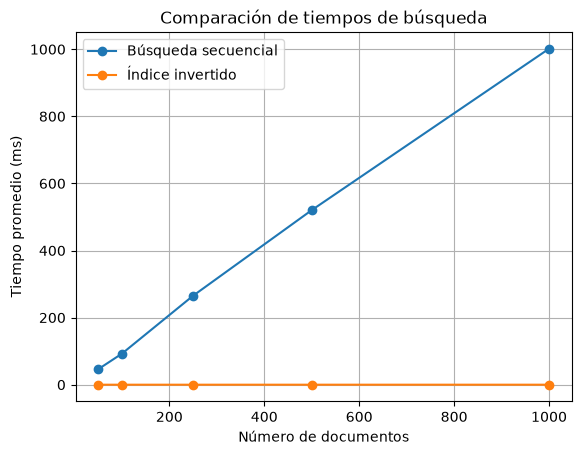

In [38]:
plt.plot(
    sizes,
    resultados_sec,
    marker="o",
    label="Búsqueda secuencial"
)

plt.plot(
    sizes,
    resultados_inv,
    marker="o",
    label="Índice invertido"
)

plt.xlabel("Número de documentos")
plt.ylabel("Tiempo promedio (ms)")
plt.title("Comparación de tiempos de búsqueda")
plt.legend()
plt.grid(True)

plt.show()

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.